# 🔄 Reinforcement Learning!

📊 **High-level goal:**
Train an agent (the “learner”) to interact with the given environment and learn from it, so it can maximize its cumulative rewards over time.
*   **Environment:**
     *   The environment **is already created** and set up for you with the help of the
"gymnasium" library.
     *   The agent interacts with a simulated environment, which has states, accepts actions, and returns rewards. The environment resets at the beginning of each episode, and the agent takes actions within it, receiving feedback in the form of rewards.
*   **Q-table:**
     *   This table stores information about the "quality" of actions in different states.
     *   The goal of the agent is to update the Q-table over time to better estimate the value of taking different actions in various states.
     *   You will initialize and learn a Q-table in this project.

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences are enough; there is no length requirement.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit this notebook to Canvas. Deliver the notebook with its outputs saved; ideally, *restart* the kernel and then *run all*.

Good luck!

---

### 📮 Imports:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from utils import *

# note: make sure to install necessary libraries like imageio, gymnasium etc.
# !pip install gymnasium

In [2]:
import gymnasium as gym
from gymnasium.spaces import Discrete, MultiDiscrete

### Environment class with necessary functions - provided for you:

In [3]:
class TrondheimEnv(gym.Env):
    metadata = {'render.modes': ['human']}

    def __init__(self, conf: dict):
        """
        Every environment should be derived from gym.Env and at least contain
        variables observation_space and action_space specifying the type of possible
        observations and actions using spaces.Box or spaces.Discrete.

        Example:
        >>> EnvTest = TrondheimEnv()
        >>> EnvTest.observation_space=spaces.Box(low=-1, high=1, shape=(3,4))
        >>> EnvTest.action_space=spaces.Discrete(2)
        """

        self.verbose = True  # Flag to control printouts

        # action definition:
        NUM_ACTIONS = 4
        self.action_space = Discrete(NUM_ACTIONS)

        self.env_image_path = conf['env_image_path']

        self.pallete = np.array([
                            [0, 0, 255],    # Blue:0:Water
                            [255, 255, 0],  # Yellow:1:Start
                            [0, 255, 0],    # Green:2:Land
                            [255, 0, 0],    # Red:3:BusLane
                            [128, 0, 128],  # Purple:4:BusStop
                            [0, 0, 0]],      # Black:5:Final Location
                           dtype=np.uint8)
                            # [128, 128, 0]], # Olive:5:Final Location

        self.neighbours = np.array([[-1,0],[0,-1],[1,0],[0,1]]) # up, left, down, right
        self.not_allowed_area = [0] # water
        self.start_class = 1 # start
        self.normal_land_class = 2 # land
        self.busstop_class = 4 # bus stop
        self.final_location_class = 5 # final location (2)

        # does the agent die when entering not_allowed_area
        self.dead_allowed = conf['dead_allowed']
        # should we start at different place each time
        self.start_random = conf['start_random']

        # read RGB image into a 3D numpy array
        img_3d = read_png_file(self.env_image_path, printDebug = False)

        # convert RGB image into 2D semantic class representation
        img_2d = make_2d(map_3d=img_3d, palette_array=self.pallete)

        # the current state of the environment
        self.observation = img_2d # initial observation - 2D semantic class
        # copy of the environment's initial state before any actions have been taken
        self.initial_observation = img_2d.copy()

        max_observation_value = np.max(img_2d)
        # observation space is a gym object (MultiDiscrete), like numpy array. It can be sampled
        observation_space = np.full_like(img_2d, fill_value=max_observation_value)
        self.observation_space = MultiDiscrete(observation_space)

        self.reward = 0
        self.terminated = False
        
    def step(self, action: int) -> tuple[np.ndarray, float, bool, dict]:
        """
        This method is the primary interface between environment and agent.

        Parameters:
            action: the index of the respective action

        Returns:
            output: information provided by the environment about its current state:
                    (observation, reward, terminated, info)

                    self.observation: The updated state of the environment (2D)
                    reward: Reward agent received for the action in this step 
                    terminated: indicate if the episode has ended
                    info: Additional information (not used, always None)

        """
        obs = self.observation # 2D array of semantic class image representation
        terminated = False
        info = None
        
        # just start and see where it goes
        start_idx = np.argwhere(obs == self.start_class)[0]
        # action is: 0:up, 1:left, 2:down, 3:right
        next_idx = start_idx + self.neighbours[action]
        reward = self.reward
        
        if self.verbose:
          print('Next step towards: ')

        if not is_valid_idx(image_2D=obs, selected_idx=next_idx):
            next_idx = start_idx
            if self.verbose:
                print('Hey there, you cannot escape outside of the environment')

        # now decide what happens next
        if obs[tuple(next_idx)] == self.normal_land_class:
            if self.verbose:
                print('Green Land class area')

        # check if it is a non allowed area
        if obs[tuple(next_idx)] in self.not_allowed_area:
            if self.verbose:
                print('The move is not allowed')
            if self.dead_allowed:
                # penalize the agent if allowed to die. Terminate
                reward = -1
                terminated = True
            else:
                # if NOT allowed to die, reset the next position to current one - prevent the move
                next_idx = start_idx

        # if the player is at a bus stop
        elif obs[tuple(next_idx)] == self.busstop_class:
            if self.verbose:
                print('A bus stop')

            # get the bus stop that is not the next step
            bus_stop_indices = np.argwhere(obs == self.busstop_class)
            # flip the next state to the other side of the stop
            if np.array_equal(next_idx, bus_stop_indices[0]):
                # teleport the agent from bus stop 0 to bus stop 1
                next_idx = bus_stop_indices[1]
            else:
                # teleport the agent from bus stop 1 to bus stop 0
                next_idx = bus_stop_indices[0]

        # and the Final Location
        elif obs[tuple(next_idx)] == self.final_location_class:
            if self.verbose:
                print('Final Location - well done!')
                print('You have discovered the Final Location of AI center in Trondheim')
            reward = 10
            terminated = True

        # now we need to change the observation space
        # i.e. update the environment’s state to reflect the agent's movement

        # if agent’s current position was initial start position
        if self.initial_observation[tuple(start_idx)] == self.start_class:
            # if true, update observation - mark the start position as neutral area
            self.observation[tuple(start_idx)] = self.normal_land_class
        else:
            # if current position not the initial start one
            # restores position in self.observation to its original value from self.initial_observation
            # re-color the observation as where you were if not start position
            self.observation[tuple(start_idx)] = self.initial_observation[tuple(start_idx)]

        # sets the new position of the agent as the next start position
        self.observation[tuple(next_idx)] = self.start_class

        self.terminated = self.terminated or terminated

        return self.observation, reward, terminated, info


    def reset(self) -> np.ndarray:
        """
        This method resets the environment to its initial values.
        """

        img_3d = read_png_file(self.env_image_path, printDebug = False)
        img_2d = make_2d(map_3d=img_3d, palette_array=self.pallete)

        if self.start_random:
          # we need to move the start to another place
          img_2d = swap_values(arr=img_2d, value1=1, value2=2)

        self.observation = img_2d
        self.initial_observation = img_2d.copy()

        max_observation_value = np.max(img_2d)
        observation_space = np.full_like(img_2d, fill_value=max_observation_value)
        self.observation_space = MultiDiscrete(observation_space)

        self.reward = 0
        self.terminated = False

        return self.observation
        
    def get_state_id(self):
        """
        This method converts the observation to a unique id that we will use to index the Q table.
        """
        rows, cols = self.observation.shape
        grid_size = rows * cols

        agent_pos = np.argwhere( self.observation == self.start_class)[0]
        agent_row, agent_col = agent_pos[0], agent_pos[1]

        grid_index = (agent_row * cols) + agent_col

        return grid_index

    def render(self, mode: str = "", close: bool = False) -> np.ndarray:
        """
        This method provides the option to render the environment's behavior to a
        window which should be readable to the human eye if mode is set to 'human'.
        """
        render_ready_arr = make_3d(map_2d=self.observation, palette_array=self.pallete)
        if mode == "human":
            plt.imshow(render_ready_arr)
            plt.show()
            plt.close()
        return render_ready_arr

    def close(self):
        img_3d = read_png_file(self.env_image_path)
        img_2d = make_2d(map_3d=img_3d, palette_array=self.pallete)
        self.observation = img_2d
        self.initial_observation = img_2d.copy()


### Configuring and loading the environment:

#### 🔎📉  Let's first visualize our simple toy environment

In [4]:
# This is how you create a configuration for the environment
env_config = {
    'env_image_path':'image_simple.png',
    'dead_allowed':False,
    'start_random':False,
}


if not os.path.exists(env_config['env_image_path']):
  # make sure you have the folder and the image
  print(f"Error: The image path {env_config['env_image_path']} does not exist.")
else:
  # if everything fine, we create the environment
  env = TrondheimEnv(conf=env_config)
  print(f"Environment successfully created")

Environment successfully created


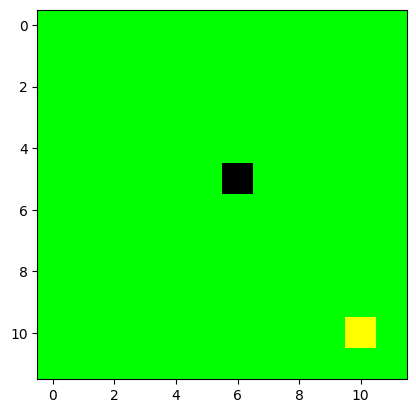

In [5]:
# visualize the environment. Yellow is where we are, Black is where we want to go
env.reset()
_ = env.render("human")

Let's see how actions work:

In [6]:
action_dict = {
    'up':0,
    'left':1,
    'down':2,
    'right':3,
}

Next step towards: 
Green Land class area
Reward for action up is: 0


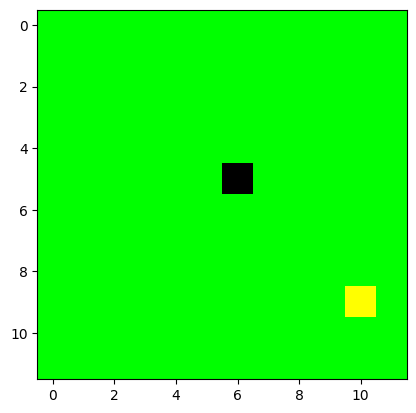

Observation space looks like this:
[[2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 5 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 1 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]]


In [7]:
# select your action here
# you are encouraged to play further with this
my_action = 'up'

# now take a step through the environment by taking this action
obs, rew, term, info = env.step(action_dict[my_action])
print(f"Reward for action {my_action} is: {rew}")
env.render("human")

print(f"Observation space looks like this:\n{obs}")

## 🐮 Problem 1: Q-learning in a simple toy environment
### ❗️ The problem
In the first problem, you will train an agent to navigate from a start position (yellow) to a goal position (black) in a simple grid environment using Q-learning.

### 📋 Formal requirements
1. **Implementation**:
   - Initialize the Q-table
   - Write the necessary helper functions for Q-learning (exploration rate, learning rate and action selection)
   - Choose and tune the hyperparameters
   - Train the agent using Q-learning
   - Run one episode with the trained agent and verify that it reaches the goal
   - Visualize the learned Q-values as heatmaps
2. **Discussion**:
   - Why do we need an exploration rate?
   - Why do we update the learning rate?
   - Explain all terms of the Q-learning update rule.
   - What do the heatmaps show?
   - Why does the Q-table have 144 states?
   - What happens with γ = 0 or γ = 1?
   - Every step gives reward 0. How does the agent still learn the shortest path?
   - What happens if the exploration rate is 0 from the start?
   - Why do we set the exploration rate to 0 when we show the trained agent?

### 🐣 Let's learn how to do this in a simple environment

In [8]:
env_config = {
    'env_image_path':'image_simple.png',
    'dead_allowed':False,
    'start_random':False,
}

if not os.path.exists(env_config['env_image_path']):
  print(f"Error: The image path {env_config['env_image_path']} does not exist.")
else:
  env = TrondheimEnv(conf=env_config)
  print(f"Environment successfully created")

Environment successfully created


### Step 1: Initialize Q table

In [9]:
# Task 1: Initialize Q table
"""
TODO: given the environment, initialize the Q table
"""

# Tip: pay attention to the dimensions of Q table
# Tip: how many states does the table have, how many actions
# Okei, så tabellem, eller states er 12*12 = 144 ulike states. Og 4 ulike actions. Og det er vel antallet states som er Q-verdiene? Man trenger en Q-verdi for hver state? Gitt forelesningsnotatene
# hvor de bruker 9 verdier i Q, for å presentere ett 3x3 rutenett. 
# .shape under motiverer til numpy-array

# ====================================
# YOUR CODE GOES HERE
q_table = np.zeros((144, 4))
# ====================================

In [10]:
# take a look at the initial Q table
print(f"Q table has this shape: {q_table.shape}\n")

# you may want to print Q table, or parts of it, to get the vibe
print(q_table[:10])
print(f"\n")
print(q_table[135:])

Q table has this shape: (144, 4)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


### ❓ Why does the Q-table have 144 states?

In [11]:
# Det er et rutenett med 12x12 mulige plasser for den gule firkanten å flytte seg.

### Step 2: Write necessary helper functions for Q-learning

In [12]:

def update_explore_rate(episode: int, epsilon_min: float, max_episodes: int, start: float):
    """controls the balance between exploration and exploitation"""
    # ====================================
    # YOUR CODE GOES HERE: return updated explore_rate
    # Her skal den også avta etter hvert, men ikke gå helt til 0
    # ====================================
    current_epsilon = start
    share = episode / max_episodes
    new_epsilon = current_epsilon * (1-share)
    return max(new_epsilon, epsilon_min)

# Helt tullete å ikke ha med en start-verdi

def update_learning_rate(episode: int, min_learning_rate: float, max_episodes: int, start: float):
    """controls how aggressively the agent updates its knowledge"""
    # ====================================
    # YOUR CODE GOES HERE: return updated learning_rate
    # Det er lurt å minke learningraten i løpet av treningen. Synes det var veldig kuk å ha denne funksjonen først, når learning_rate defineres senere.
    # Jaja, kanskje det var meningen at det skulle gjøres senere. 
    # ====================================
    current_learning_rate = start
    share = episode / max_episodes
    new_learning_rate = current_learning_rate * (1-share)
    return max(new_learning_rate, min_learning_rate)


# Forelesningsnotatenes choose_action
def update_action(env, state: int, explore_rate: float, q_table: np.ndarray) -> int:
    """uses the exploration rate to decide whether to take a random action (explore) 
    or to act according to the learned Q-values (exploit)""" 
    # ====================================
    # YOUR CODE GOES HERE: return an action
    # ====================================
    if np.random.random() < explore_rate:
        return env.action_space.sample() # "en action tilfeldig samplet fra environments action space"
    else:
        return np.argmax(q_table[state])


### ❓ Why do we need an exploration rate?


In [13]:
# Dette trenger vi fordi vi update action trenger å vite hvor tilfeldig actionen den skal gjøre skal være.

### ❓ Why do we update the learning rate?


In [14]:
# We update the learning rate, because as the agent learns more, the importance of the last step decreases. Altså i starten er det lurt å lære mye av det forrige steget, men etter hvert ønsker vi heller at den lærer mindre
# av det forrige steget, og mer av tidligere steg. 

### Step 3: Play with Hyperparameters

In [15]:
# ====================================
# YOUR CODE GOES HERE: replace None with your values
# ====================================
# GAMMA = 0.6
# NUM_EPISODES = 100
# MAX_STEPS_PER_EPISODE = 100
# EPSILON = 0.8
# EPSILON_MIN = 0.2
# MIN_LEARNING_RATE = 0.5

# Flytter verdiene til den andre cella, helt noldus å ikke ha de i samme

### 🐤 Now use Q learning to learn the Q table
### Step 4: Train the agent using Q-learning

The Q-value update equation, derived from Bellman equation is as follows:


$$
Q(s, a) \gets Q(s, a) + \alpha \cdot \Big[ R(s, a) + \gamma \cdot \max_{a'} Q(s', a') - Q(s, a) \Big]
$$

### ❓ Explain all terms of the Q-learning update rule.
- **Q(s, a)**: 
- **α**: 
- **R(s, a)**: 
- **γ**: 
- **s'**: 
- **a'**: 
- **max Q(s', a')**: 

In [16]:
# Suggestion: you can wrap the code to learn Q-table in a function,
# which you can also reuse in Problem 2

# result of the training is:
#   updated Q table (q_table)
#   total_reward
#   you are free to add others, if you wish

env.verbose = False # disable printouts while training

# Hyperparametere
GAMMA = 0.9
NUM_EPISODES = 100
MAX_STEPS_PER_EPISODE = 200
EPSILON = 1
EPSILON_MIN = 0.02
MIN_LEARNING_RATE = 0.5

# Hmmm det virker som at antall steps er viktigere enn number of episodes
# ====================================
# YOUR CODE GOES HERE
# ====================================

total_reward = None
explore_rate = None
learning_rate = 1



# iterate over number of episodes
    # remember to reset the state!
    # update the exploration and learning rate
    # iterate over number of steps in each Episode
        # Tip: use helper functions defined above to navigate the environment
        # get action and step through the environment
        # update the q-table
        # check if we are done
def train(env, table, num_episodes):

    for i in range(num_episodes):
        total_reward = 0
        env.reset()
        current_state = env.get_state_id()
        current_explore_rate = update_explore_rate(episode=i, epsilon_min=EPSILON_MIN, max_episodes=num_episodes, start=EPSILON)
        current_learning_rate = update_learning_rate(i, MIN_LEARNING_RATE, num_episodes, learning_rate)
        number_of_steps = 0
        for step in range(MAX_STEPS_PER_EPISODE):
            action = update_action(env, current_state, current_explore_rate, table)
            _, reward, done, info = env.step(action)
            new_state = env.get_state_id()
            if done:
                table[current_state][action] = (1-current_learning_rate) * table[current_state][action] + (current_learning_rate * reward)
                total_reward += reward
                number_of_steps += 1
                break
            else:
                table[current_state][action] = (1-current_learning_rate) * table[current_state][action] + (current_learning_rate) * (reward + GAMMA * np.max(table[new_state]))
                total_reward += reward
                current_state = new_state
                number_of_steps += 1
        print(f"Episode: {i}  Total_reward: {total_reward} Learning rate: {current_learning_rate:.3f} Steps: {number_of_steps} Explore rate: {current_explore_rate:.3f}")
    return table, total_reward, current_explore_rate
           
            

q_table, total_reward, explore_rate = train(env, q_table, NUM_EPISODES)


    

        
# Tip : print variables of interest, like episode, total_reward, explore_rate
# print(f"Episode: {episode}  Total_reward: {total_reward}  Explore rate: {explore_rate}")
# print("Final Q values: ", q_table)

Episode: 0  Total_reward: 0 Learning rate: 1.000 Steps: 200 Explore rate: 1.000
Episode: 1  Total_reward: 0 Learning rate: 0.990 Steps: 200 Explore rate: 0.990
Episode: 2  Total_reward: 0 Learning rate: 0.980 Steps: 200 Explore rate: 0.980
Episode: 3  Total_reward: 10 Learning rate: 0.970 Steps: 74 Explore rate: 0.970
Episode: 4  Total_reward: 10 Learning rate: 0.960 Steps: 79 Explore rate: 0.960
Episode: 5  Total_reward: 10 Learning rate: 0.950 Steps: 160 Explore rate: 0.950
Episode: 6  Total_reward: 10 Learning rate: 0.940 Steps: 41 Explore rate: 0.940
Episode: 7  Total_reward: 0 Learning rate: 0.930 Steps: 200 Explore rate: 0.930
Episode: 8  Total_reward: 10 Learning rate: 0.920 Steps: 193 Explore rate: 0.920
Episode: 9  Total_reward: 10 Learning rate: 0.910 Steps: 184 Explore rate: 0.910
Episode: 10  Total_reward: 0 Learning rate: 0.900 Steps: 200 Explore rate: 0.900
Episode: 11  Total_reward: 10 Learning rate: 0.890 Steps: 106 Explore rate: 0.890
Episode: 12  Total_reward: 0 Learn

In [17]:
print(f"Total reward after training: {total_reward}, total Explore rate after training: {explore_rate:.4f}")

Total reward after training: 10, total Explore rate after training: 0.0200


### 🐥 Let's see this in action

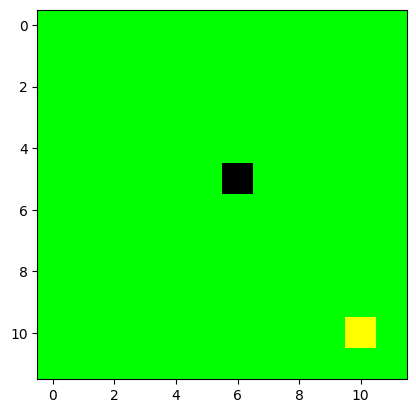

Total_reward:  10


In [18]:
# now we show one episode
# yellow spot should be able to find black spot here
# If you want to see frame by frame, remember to pass "human" as argument in env.render()!

env.verbose = False # set to True to enable messages
NUM_STEPS = 32

observation = env.reset()
state_id = env.get_state_id()
total_reward = 0

image_samples = []

img = env.render("human")
for _ in range(NUM_STEPS):
    action = update_action(env, state_id, 0, q_table) # explore rate 0: always pick the best action
    observation, reward, terminated, info = env.step(action)
    state_id = env.get_state_id()
    total_reward += reward
    img = env.render()
    image_samples.append(img)
    if terminated:
        break

print(f"Total_reward: ", total_reward)

MovieWriter ffmpeg unavailable; using Pillow instead.


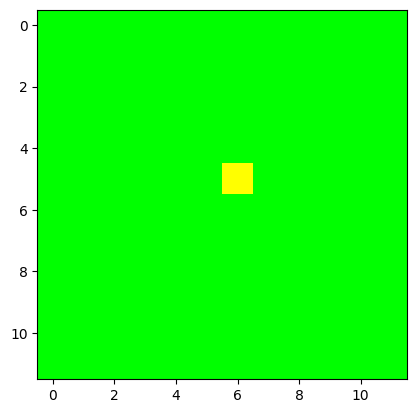

In [19]:
# let's make an animation of this, because it's fun
# nothing for you to do here - just run the code
# and open the animation.gif in output/

import os
import matplotlib.animation as animation

height = img.shape[0]
width = img.shape[1]

output_folder = 'output'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)


fig = plt.figure()
imgs = []
for i in range(len(image_samples)):
    im = plt.imshow(image_samples[i].reshape(height, width, 3), animated=True)
    imgs.append([im])

animate = animation.ArtistAnimation(fig, imgs, interval=80, blit=True, repeat_delay=1000)
filename_gif = os.path.join(output_folder, 'animation.gif')
animate.save(filename_gif)
plt.show()

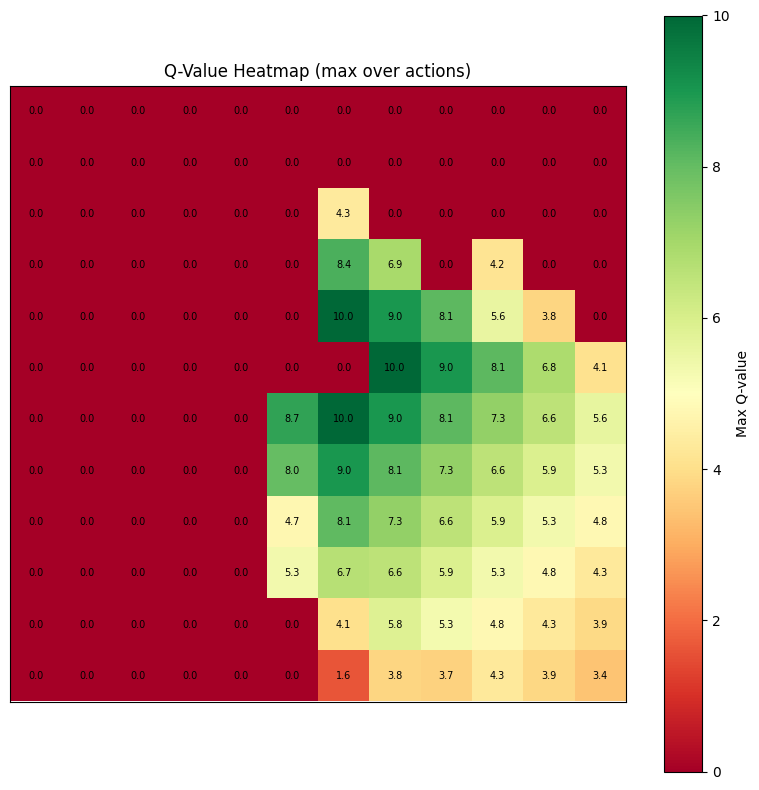

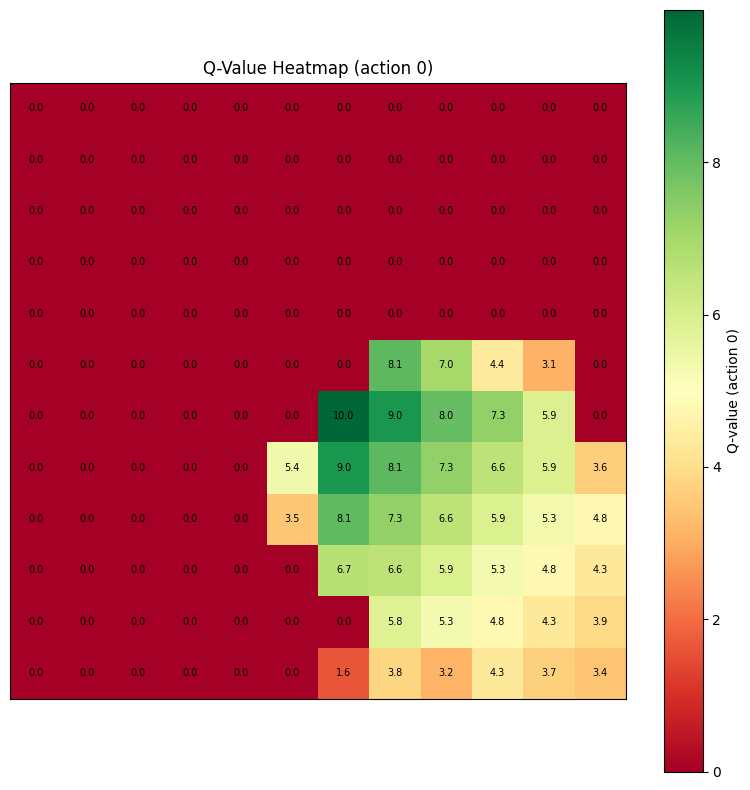

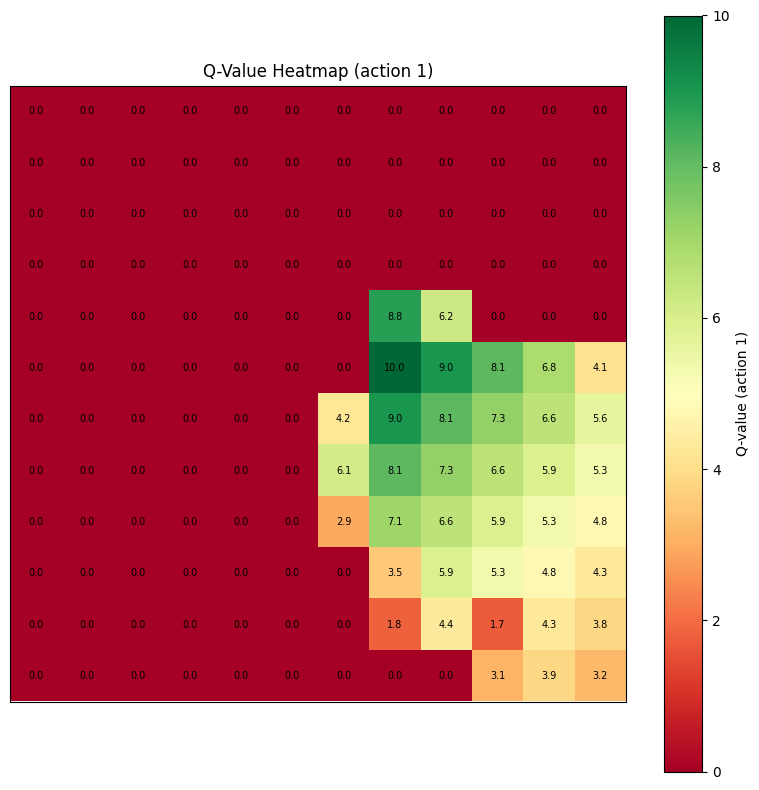

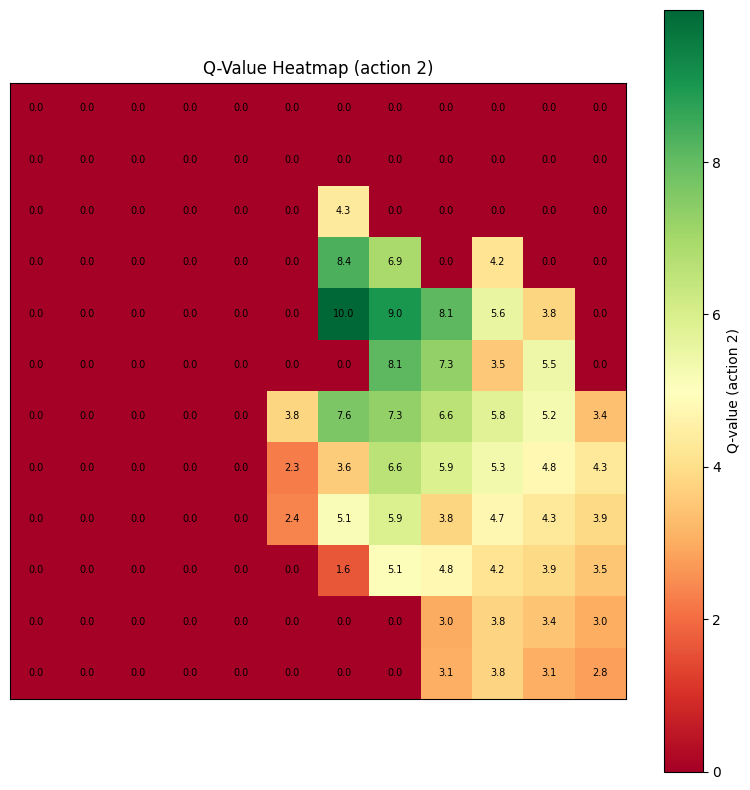

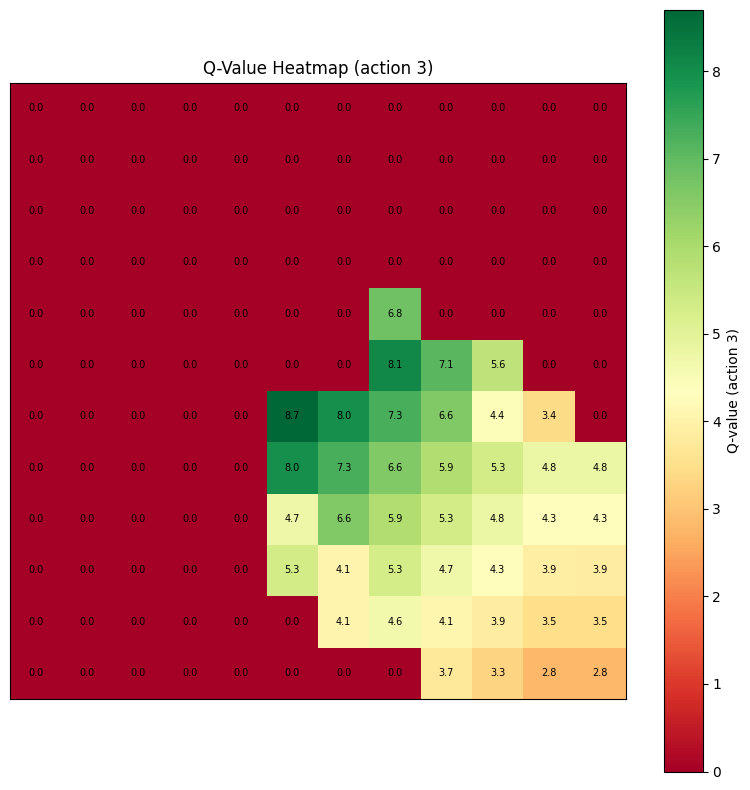

In [20]:
# Let's visualize the Q values now!
def show_q_heatmap(env, q_table, action: int = None):
    # ====================================
    # YOUR CODE GOES HERE
    # ====================================
    nrows, ncols = env.observation_space.shape
    if action is None:
        values = q_table.max(axis=1)
    else:
        values = q_table[:, action]
    q_grid = values.reshape(nrows, ncols).astype(float)
    # ====================================
    fig, ax = plt.subplots(figsize=(8, 8))
    im = ax.imshow(q_grid, cmap='RdYlGn', interpolation='nearest')
    fig.colorbar(im, ax=ax, label='Max Q-value' if action is None else f'Q-value (action {action})')
    
    for r in range(nrows):
        for c in range(ncols):
            if not np.isnan(q_grid[r, c]):
                ax.text(c, r, f'{q_grid[r, c]:.1f}', ha='center', va='center',
                        fontsize=7, color='black')
    
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title("Q-Value Heatmap " + (f"(action {action})" if action is not None else "(max over actions)"))
    fig.tight_layout()
    plt.show()

show_q_heatmap(env, q_table)
show_q_heatmap(env, q_table, 0)
show_q_heatmap(env, q_table, 1)
show_q_heatmap(env, q_table, 2)
show_q_heatmap(env, q_table, 3)

In [21]:
print(q_table.shape)
print(f"Obs space dimensions :{env.observation_space.shape}")

(144, 4)
Obs space dimensions :(12, 12)


In [22]:
q_table.argmax(axis=1).reshape(env.observation_space.shape)

array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 2, 2, 0, 2, 0, 0],
       [0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1],
       [0, 0, 0, 0, 0, 3, 0, 0, 1, 1, 1, 1],
       [0, 0, 0, 0, 0, 3, 0, 0, 1, 1, 1, 1],
       [0, 0, 0, 0, 0, 3, 0, 0, 1, 0, 0, 1],
       [0, 0, 0, 0, 0, 3, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 1, 0]])

In [23]:
env.close()

image has more than 3 channels, only first 3 channels are used there are (12, 12, 4) channels


### ❓ What do the heatmaps show?

In [24]:
# Heatmapsene viser de forskjellige rewardsene gitt en action, og det er et plott for hver action (up, left, down, right). Hver rute viser rewarden for å gjøre de respektive actionesene når man står i den ruta. 

### ❓ What happens with γ = 0 or γ = 1?

In [25]:
# Hvis gamma er 0 tar den bare hensyn til tidligere rewards, og ingen hensyn til fremtidige rewards. Det motsatte gjelder for gamme = 1.

### ❓ Every step gives reward 0. How does the agent still learn the shortest path?

In [26]:
# Det eneste som ikke gir reward 0, er hvis den treffer riktig endpoint, men agenten lærer seg fortsatt shortest path på grunn av at Q-tabellen oppdateres. 
# I tillegg gjør den også tilfeldige valg med exploration rate, og bruker dette til å oppdatere Q-verdien.

### ❓ What happens if the exploration rate is 0 from the start?

In [27]:
# Hvis exploration rate er 0 fra start, så gjør den ingen tilfeldige valg i starten, altså den følger bare Q-tabellen, som jo også kun har verdier lik 0 i hele tabellen.
# Da vil argmax bare returnere den første verdien siden alle er 0, og den vil gå opp hver gang.

### ❓ Why do we set the exploration rate to 0 when we show the trained agent?

In [28]:
# Fordi "trained agent" refererer til en agent som har lært seg det riktige, og da skal det i utgangspunktet ikke være behov for noe tilfeldighet. 
# Det blir litt som at hvis man øver til eksamen, helt til man kan det godt nok, så skal det ikke være behov for å gjette på noen oppgaver.

## 🌉 Problem 2: Q-learning in the Trondheim environment
### ❗️ The problem
In the second problem, you will train an agent to navigate from a start position to a goal position using Q-learning, similar to the first problem, but now in a larger and more complex map of Trondheim with water (not allowed), land, bus lanes and bus stops (which teleport the agent to the other bus stop).

### 📋 Formal requirements
1. **Implementation**:
   - Initialize the Q-table
   - Reuse the helper functions for Q-learning from Problem 1
   - Choose and tune the hyperparameters
   - Train the agent using Q-learning
   - Plot the number of steps per episode during training
   - Run one episode with the trained agent and verify that it reaches the goal
2. **Discussion**:
   - Has the training converged?
   - Does the agent use the bus stops? Why or why not?
   - What changes with `dead_allowed=True` or `start_random=True`?

In [29]:
env_config = {
    'env_image_path':'image_TRD.png',
    'dead_allowed':False,
    'start_random':False,
}

if not os.path.exists(env_config['env_image_path']):
  print(f"Error: The image path {env_config['env_image_path']} does not exist.")
else:
  env = TrondheimEnv(conf=env_config)
  print(f"Environment successfully created")

Environment successfully created


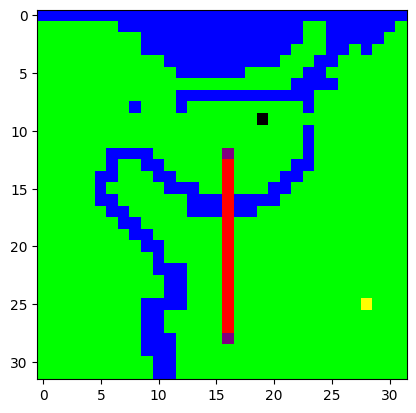

In [30]:
env.reset()
_ = env.render('human')

Next step towards: 
Green Land class area
0


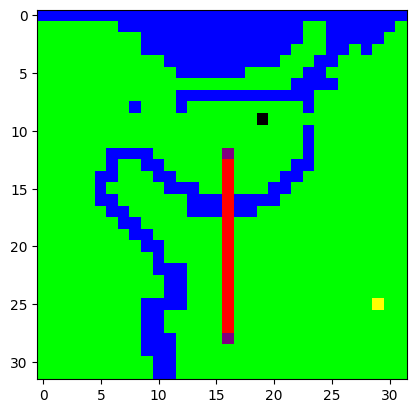

Observation space looks like this:
[[0 0 0 ... 0 0 0]
 [2 2 2 ... 0 0 2]
 [2 2 2 ... 0 2 2]
 ...
 [2 2 2 ... 2 2 2]
 [2 2 2 ... 2 2 2]
 [2 2 2 ... 2 2 2]]


In [31]:
# select the action here
my_action = 'right'

# here is your action
obs, rew, term, info = env.step(action_dict[my_action])
print(rew)
_ = env.render('human')

print(f"Observation space looks like this:\n{obs}")

### Step 1: Initialize Q table

In [32]:
# ====================================
# YOUR CODE GOES HERE
# ====================================
# 32x32
q_table_trd = np.zeros((1024, 4))

### Step 2: Write necessary helper functions for Q-learning

In [33]:
# Task 2: Write necessary helper functions for Q-learning
# ====================================
# YOUR CODE GOES HERE
# ====================================

# YOU DON'T NEED TO DO ANYTHING HERE. The helper functions from Problem 1 can be reused
# Kopi fra Problem 1:
def update_explore_rate(episode: int, epsilon_min: float, max_episodes: int, start: float):
    """controls the balance between exploration and exploitation"""
    # ====================================
    # YOUR CODE GOES HERE: return updated explore_rate
    # Her skal den også avta etter hvert, men ikke gå helt til 0
    # ====================================
    current_epsilon = start
    share = episode / max_episodes
    new_epsilon = current_epsilon * (1-share)
    return max(new_epsilon, epsilon_min)

# Helt tullete å ikke ha med en start-verdi

def update_learning_rate(episode: int, min_learning_rate: float, max_episodes: int, start: float):
    """controls how aggressively the agent updates its knowledge"""
    # ====================================
    # YOUR CODE GOES HERE: return updated learning_rate
    # Det er lurt å minke learningraten i løpet av treningen. Synes det var veldig kuk å ha denne funksjonen først, når learning_rate defineres senere.
    # Jaja, kanskje det var meningen at det skulle gjøres senere. 
    # ====================================
    current_learning_rate = start
    share = episode / max_episodes
    new_learning_rate = current_learning_rate * (1-share)
    return max(new_learning_rate, min_learning_rate)


# Forelesningsnotatenes choose_action
def update_action(env, state: int, explore_rate: float, q_table: np.ndarray) -> int:
    """uses the exploration rate to decide whether to take a random action (explore) 
    or to act according to the learned Q-values (exploit)""" 
    # ====================================
    # YOUR CODE GOES HERE: return an action
    # ====================================
    if np.random.random() < explore_rate:
        return env.action_space.sample() # "en action tilfeldig samplet fra environments action space"
    else:
        return np.argmax(q_table[state])

### Step 3: Play with Hyperparameters

In [34]:
# ====================================
# YOUR CODE GOES HERE
# ====================================
# GAMMA = None
# NUM_EPISODES = None
# MIN_EXPLORE_RATE = None
# MIN_LEARNING_RATE = None
# STEP_SIZE = None
# Flytter hyperparametere igjen, det er tilbakemelding til øvingsopplegget, ikkenoe vits å ha det i egen celle

### 🐤 Now use Q-learning to learn the Q-table
### Step 4: Train the agent using Q-learning

In [35]:
env.verbose = False # disable printouts while training

# ====================================
# YOUR CODE GOES HERE
# ====================================

total_reward = None
steps_per_episode = None # number of steps the agent needed in each episode, har definert i funksjonen
explore_rate = None
learning_rate = 1

# Kopi fra problem 1

# Hyperparametere
GAMMA = 0.9
NUM_EPISODES = 500
MAX_STEPS_PER_EPISODE = 1000
EPSILON = 1.0
EPSILON_MIN = 0.02
MIN_LEARNING_RATE = 0.5

# Naturligvis må vi har langt flere steg og episoder
# Hmmmm bare litt refleksjon her, men det virker som at antall steg per episode er alfa og omega
# ====================================
# YOUR CODE GOES HERE
# ====================================



# iterate over number of episodes
    # remember to reset the state!
    # update the exploration and learning rate
    # iterate over number of steps in each Episode
        # Tip: use helper functions defined above to navigate the environment
        # get action and step through the environment
        # update the q-table
        # check if we are done
def train(env, table, num_episodes):
    steps_per_episode = []
    for i in range(num_episodes):
        total_reward = 0
        env.reset()
        current_state = env.get_state_id()
        current_explore_rate = update_explore_rate(episode=i, epsilon_min=EPSILON_MIN, max_episodes=num_episodes, start=EPSILON)
        current_learning_rate = update_learning_rate(i, MIN_LEARNING_RATE, num_episodes, learning_rate)
        number_of_steps = 0
        for step in range(MAX_STEPS_PER_EPISODE):
            action = update_action(env, current_state, current_explore_rate, table)
            _, reward, done, info = env.step(action)
            new_state = env.get_state_id()
            if done:
                table[current_state][action] = (1-current_learning_rate) * table[current_state][action] + (current_learning_rate * reward)
                total_reward += reward
                number_of_steps += 1
                break
            else:
                table[current_state][action] = (1-current_learning_rate) * table[current_state][action] + (current_learning_rate) * (reward + GAMMA * np.max(table[new_state]))
                total_reward += reward
                current_state = new_state
                number_of_steps += 1
        steps_per_episode.append(number_of_steps)
        print(f"Episode: {i}  Total_reward: {total_reward} Learning rate: {current_learning_rate:.3f} Steps: {number_of_steps} Explore rate: {current_explore_rate:.3f}")
    return table, total_reward, current_explore_rate, steps_per_episode
           
            

q_table_trd, total_reward, explore_rate, steps_per_episode = train(env, q_table_trd, NUM_EPISODES)

Episode: 0  Total_reward: 0 Learning rate: 1.000 Steps: 1000 Explore rate: 1.000
Episode: 1  Total_reward: 10 Learning rate: 0.998 Steps: 509 Explore rate: 0.998
Episode: 2  Total_reward: 10 Learning rate: 0.996 Steps: 527 Explore rate: 0.996
Episode: 3  Total_reward: 0 Learning rate: 0.994 Steps: 1000 Explore rate: 0.994
Episode: 4  Total_reward: 0 Learning rate: 0.992 Steps: 1000 Explore rate: 0.992
Episode: 5  Total_reward: 10 Learning rate: 0.990 Steps: 607 Explore rate: 0.990
Episode: 6  Total_reward: 0 Learning rate: 0.988 Steps: 1000 Explore rate: 0.988
Episode: 7  Total_reward: 0 Learning rate: 0.986 Steps: 1000 Explore rate: 0.986
Episode: 8  Total_reward: 0 Learning rate: 0.984 Steps: 1000 Explore rate: 0.984
Episode: 9  Total_reward: 10 Learning rate: 0.982 Steps: 733 Explore rate: 0.982
Episode: 10  Total_reward: 0 Learning rate: 0.980 Steps: 1000 Explore rate: 0.980
Episode: 11  Total_reward: 10 Learning rate: 0.978 Steps: 684 Explore rate: 0.978
Episode: 12  Total_reward:

In [36]:
print(f"Total reward after training: {total_reward}, total Explore rate after training: {explore_rate:.4f}")

Total reward after training: 10, total Explore rate after training: 0.0200


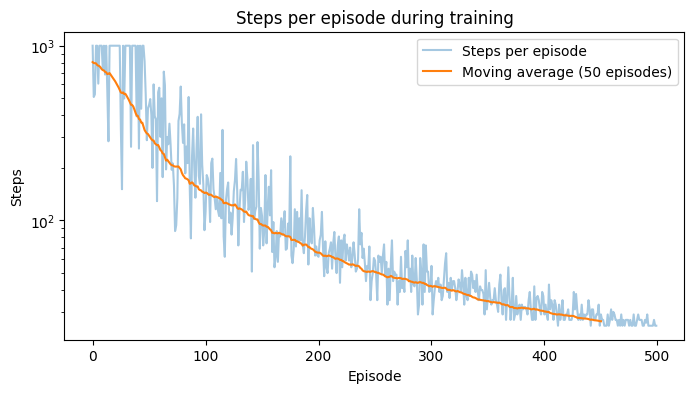

In [37]:
# plot the number of steps the agent needed in each episode
plt.figure(figsize=(8, 4))
plt.plot(steps_per_episode, alpha=0.4, label='Steps per episode')
plt.plot(np.convolve(steps_per_episode, np.ones(50) / 50, mode='valid'), label='Moving average (50 episodes)')
plt.yscale('log')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.title('Steps per episode during training')
plt.legend()
plt.show()

### ❓ Has the training converged?

In [38]:
# Ja, vi ser at grafen retter seg ut mot slutten. Da kan det virke som at 25 steg er korteste vei, og at den har lært seg korteste vei. Outputen
# fra cellen over, viser også at de 4 siste episodene alle bruker 25 steg. 

### 🐥 Let's see one episode

In [39]:
env.verbose = False
STEP_SIZE = 100

image_samples = []  # Array to store images

observation = env.reset()
state_id = env.get_state_id()
total_reward = 0

img = env.render()
for _ in range(STEP_SIZE):
    action = update_action(env, state_id, 0, q_table_trd) # explore rate 0: always pick the best action
    observation, reward, terminated, info = env.step(action)
    state_id = env.get_state_id()
    total_reward += reward
    img = env.render()
    image_samples.append(img)
    if terminated:
        break

print(f"Total_reward: ", total_reward)

Total_reward:  10


### Simple animation of agent movement in one episode

MovieWriter ffmpeg unavailable; using Pillow instead.


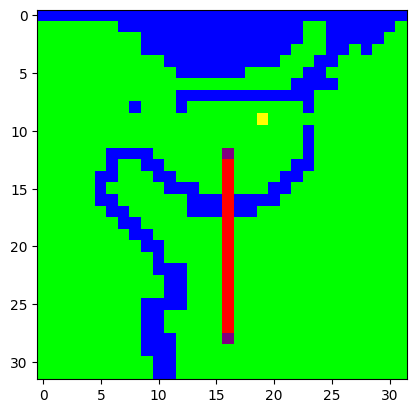

In [40]:
# let's make an animation of this, because it's fun
# nothing for you to do here - just run the code

import os
import matplotlib.animation as animation

height = img.shape[0]
width = img.shape[1]

output_folder = 'output'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

fig = plt.figure()
imgs = []
for i in range(len(image_samples)):
    im = plt.imshow(image_samples[i].reshape(height, width, 3), animated=True)
    imgs.append([im])

animate = animation.ArtistAnimation(fig, imgs, interval=80, blit=True, repeat_delay=1000)
filename_gif = os.path.join(output_folder, 'animation_trd.gif')
animate.save(filename_gif)
plt.show()

### ❓ Does the agent use the bus stops? Why or why not?

In [41]:
# Nei, nå bruker ikke agenten busstoppet. Da må den lære at bussruta er veldig effektiv. Dette krevet blant annet flere episoder, men ikke nødvendigvis flere steg per episode.
# Kanskje til og med færre steg per episode?? fordi bussen gir færre steg. Også må vi kanskje nedjustere min exploration rate og min learning rate. Hmmmm jeg prøvde, men jeg fikk det 
# fortsatt ikke til.

# Rettelse: etter å ha endret hyperparametere, så bruker den nå bussen! Dette er med 500 episoder. Det er da, som sagt hyperparameterne som avgjør. Jeg oppjusterte expolration rate til 1 også, 
# at den starter på 1. 

### ❓ What changes with `dead_allowed=True` or `start_random=True`?

In [42]:
# Det virker som at den sliter veldig hvis start_random = True, og samme hvis dead_allowed=True, altså hvis den kan dø??

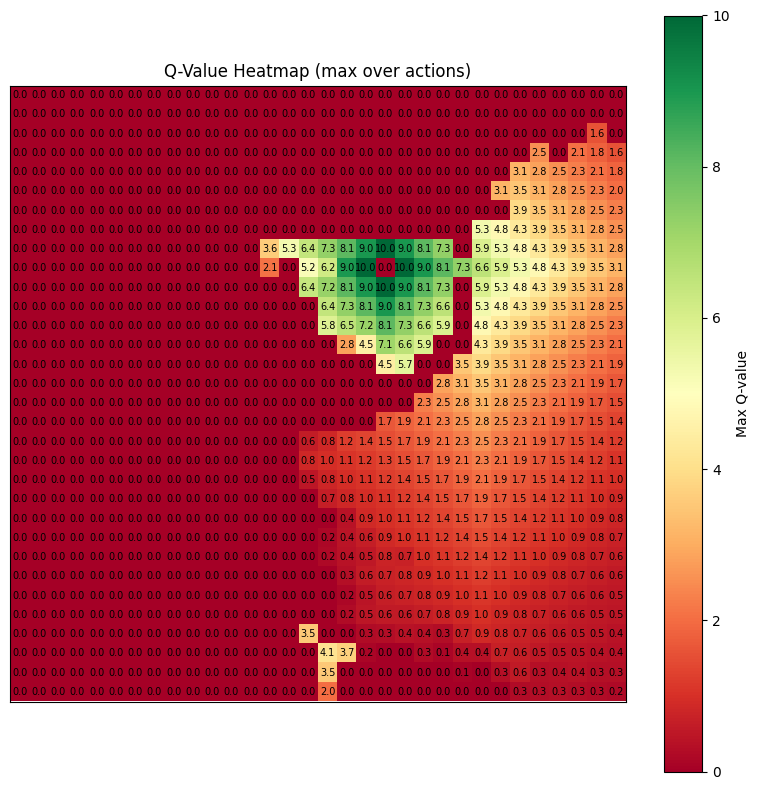

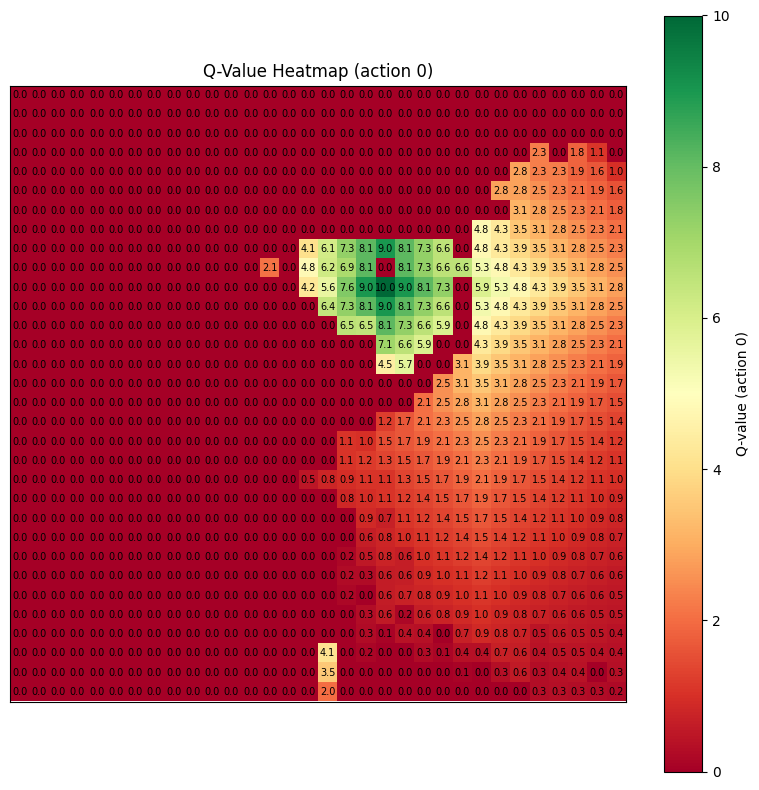

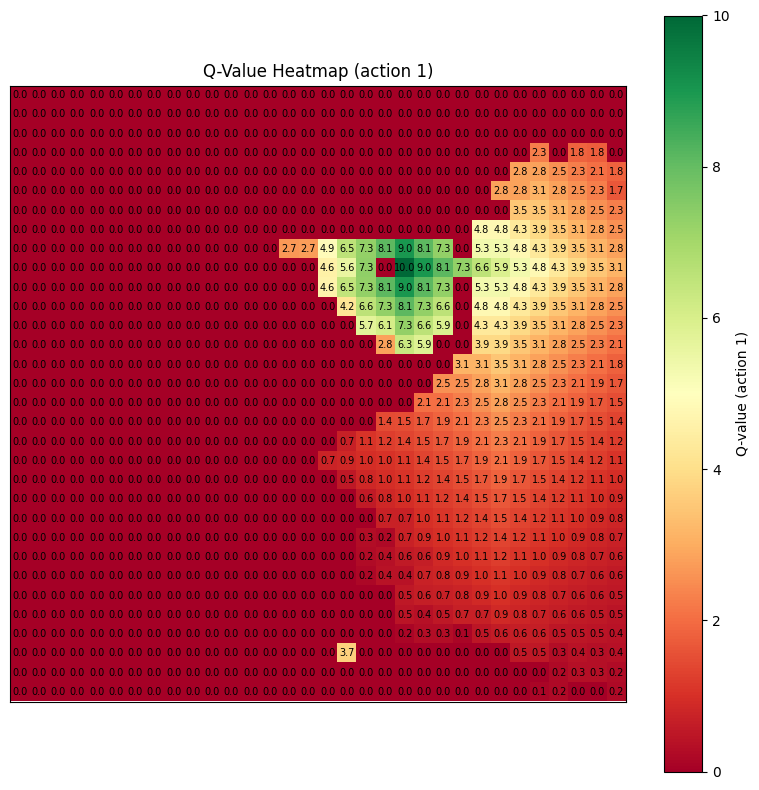

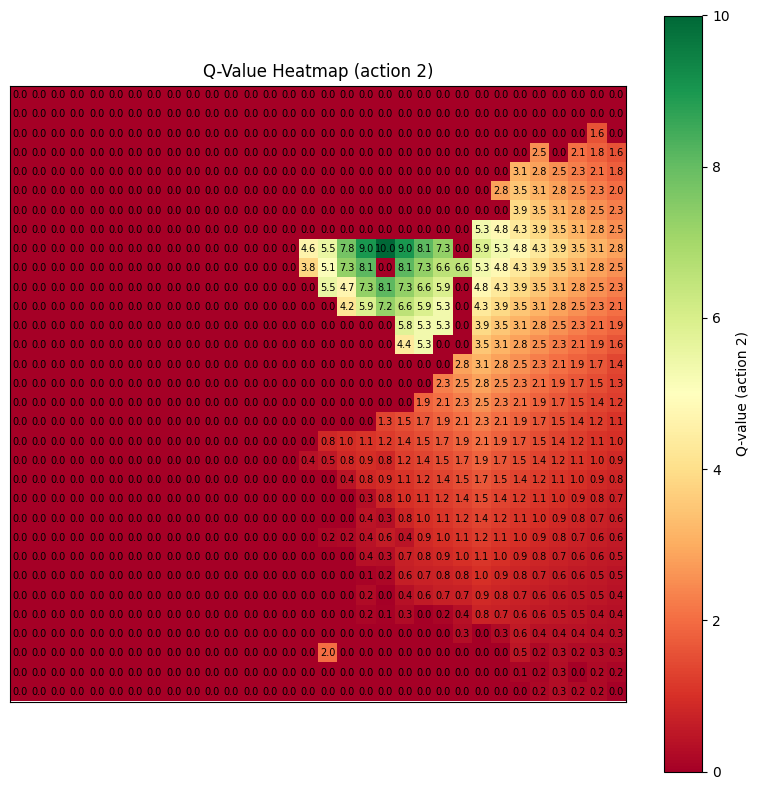

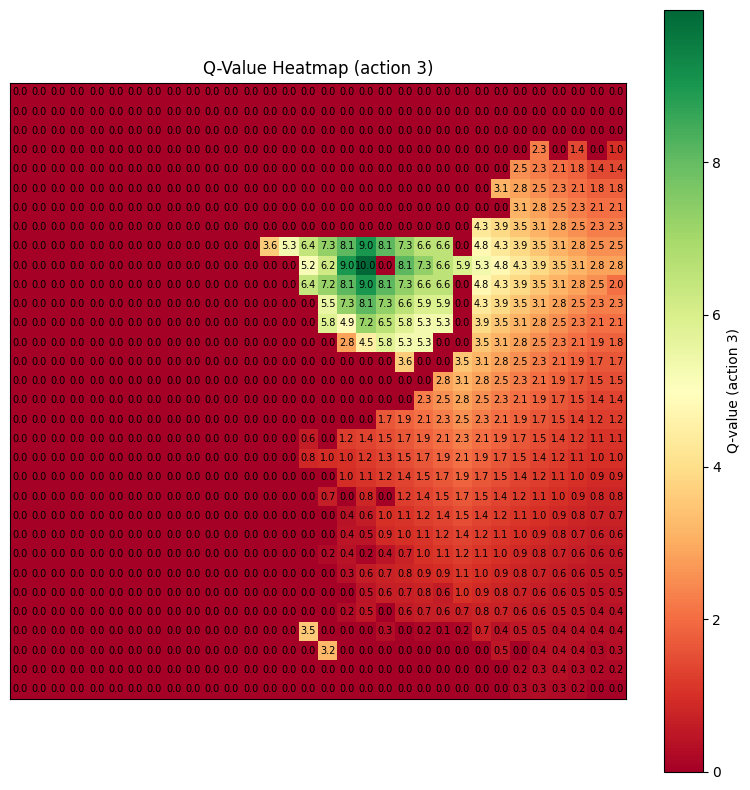

In [43]:
# ====================================
# YOUR CODE GOES HERE: plot the q values!
# ====================================
# Kopi av koden fra Problem 1
# Let's visualize the Q values now!
def show_q_heatmap(env, q_table_trd, action: int = None):
    # ====================================
    # YOUR CODE GOES HERE
    # ====================================
    nrows, ncols = env.observation_space.shape
    if action is None:
        values = q_table_trd.max(axis=1)
    else:
        values = q_table_trd[:, action]
    q_grid = values.reshape(nrows, ncols).astype(float)
    # ====================================
    fig, ax = plt.subplots(figsize=(8, 8))
    im = ax.imshow(q_grid, cmap='RdYlGn', interpolation='nearest')
    fig.colorbar(im, ax=ax, label='Max Q-value' if action is None else f'Q-value (action {action})')
    
    for r in range(nrows):
        for c in range(ncols):
            if not np.isnan(q_grid[r, c]):
                ax.text(c, r, f'{q_grid[r, c]:.1f}', ha='center', va='center',
                        fontsize=7, color='black')
    
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title("Q-Value Heatmap " + (f"(action {action})" if action is not None else "(max over actions)"))
    fig.tight_layout()
    plt.show()

show_q_heatmap(env, q_table_trd)
show_q_heatmap(env, q_table_trd, 0)
show_q_heatmap(env, q_table_trd, 1)
show_q_heatmap(env, q_table_trd, 2)
show_q_heatmap(env, q_table_trd, 3)